# Introduction to AI — Intermediate Examples

**Notebook status:** execution below is saved from a local run. Python 3.13.14; deterministic, synthetic examples; no API credentials or external services.

## Section A — Introduction

Fit class means and inspect evaluation, error counts, and time-aware splits.

**Prerequisites:** Python 3.11+, basic values and function calls. Install notebook support with `python -m pip install -e ".[notebooks]"`. **Objectives:** trace the code, explain its output, identify limitations, and suggest a real-world safety boundary. Full theory: [lesson notes](../lessons/01_introduction_to_artificial_intelligence.md).

In [1]:
import sys
import matplotlib

print(f"Python {sys.version.split()[0]} | matplotlib {matplotlib.__version__}")

Python 3.13.14 | matplotlib 3.10.8


This environment cell records the actual interpreter and plotting-library versions used for this notebook execution. Minimum compatible dependency versions are documented in the course `pyproject.toml`.

## Section B — Beginner explanation

A label is a known answer paired with an example. A centroid is the mean value for one class. A nearest-centroid prediction chooses the closest mean.

The code cells are runnable Python. Explanations before and after each cell distinguish the expected behavior from the actual output saved by this execution.

## Section C — First Python example

Read the inputs and operations before running. The output below is captured from actual execution.

In [2]:
training = [(10.0, "normal"), (12.0, "normal"), (80.0, "review"), (90.0, "review")]
centers = {label: sum(x for x, y in training if y == label) / sum(y == label for _, y in training)
           for _, label in training}
query = 70.0
guess = min(centers, key=lambda label: abs(query - centers[label]))
print("centers:", centers, "| query:", query, "| prediction:", guess)

centers: {'normal': 11.0, 'review': 85.0} | query: 70.0 | prediction: review


**Line-by-line walkthrough:** The comprehension visits labels, filters examples for each label, computes the mean, and stores it in a dictionary. The final `min` compares absolute distances. The dataset is intentionally tiny.

The output immediately above is actual saved execution output. It occurs because the code uses the displayed deterministic input.

## Section D — Intermediate examples

This example adds a more realistic data structure or evaluation step. Inputs are documented in the code.

In [3]:
evaluation = [(11.0, "normal"), (85.0, "review"), (70.0, "review")]
rows = [(x, y, min(centers, key=lambda c: abs(x-centers[c]))) for x, y in evaluation]
correct = sum(actual == predicted for _, actual, predicted in rows)
print("(value, actual, predicted):", rows)
print(f"toy accuracy={correct}/{len(rows)}={correct/len(rows):.1%}")

(value, actual, predicted): [(11.0, 'normal', 'normal'), (85.0, 'review', 'review'), (70.0, 'review', 'review')]
toy accuracy=3/3=100.0%


This cell's output is the result of the displayed computation. New Python operations are explained in the code and can be inspected interactively.

## Section E — Advanced examples

This example adds an edge case, metric, or validation concern. Consider both computational behavior and decision consequences.

In [4]:
actual, predicted = [1, 1, 0, 0, 0], [1, 0, 0, 0, 0]
tp = sum(a == p == 1 for a, p in zip(actual, predicted))
fn = sum(a == 1 and p == 0 for a, p in zip(actual, predicted))
tn = sum(a == p == 0 for a, p in zip(actual, predicted))
print({"TP": tp, "FN": fn, "TN": tn, "recall": tp/(tp+fn), "accuracy": (tp+tn)/len(actual)})

{'TP': 1, 'FN': 1, 'TN': 3, 'recall': 0.5, 'accuracy': 0.8}


Interpret each result in the context of the toy data; do not generalize the score to real deployments.

## Section F — Real-world applications

Example application: synthetic network engineering telemetry and read-only triage. The same principles apply to AI, data science, cloud monitoring, automation, and production software.

In [5]:
ordered = [(10, "normal"), (12, "normal"), (14, "normal"), (80, "review"), (90, "review")]
train, future = ordered[:3], ordered[3:]
baseline = max(x for x, _ in train)
print("earlier baseline:", baseline, "| future observations:", future)
print("Use a time split when it matches how the system will be used.")

earlier baseline: 14 | future observations: [(80, 'review'), (90, 'review')]
Use a time split when it matches how the system will be used.


No live network is contacted. Any production system needs data provenance, permissions, observability, human review, and a rollback/disable plan.

## Section G — Visualization

The chart below is rendered and embedded in this notebook's saved outputs. It uses the small synthetic demonstration data.

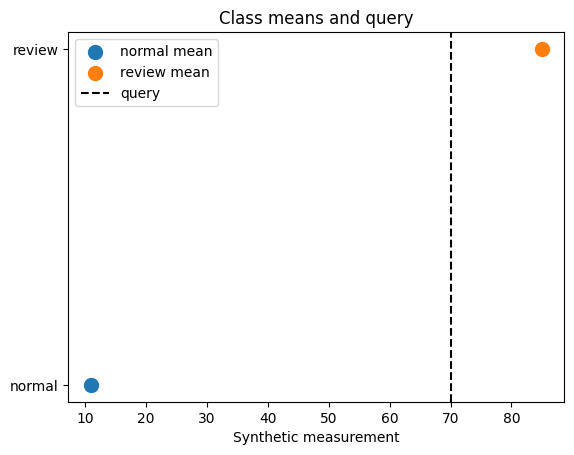

In [6]:
import matplotlib.pyplot as plt
for label, center in centers.items():
    plt.scatter(center, label, s=100, label=f"{label} mean")
plt.axvline(query, color="black", linestyle="--", label="query")
plt.xlabel("Synthetic measurement")
plt.title("Class means and query")
plt.legend()
plt.show()

The figure supports visual intuition only; it is not validation evidence.

## Section H — Debugging and common mistakes

The following code intentionally reaches an invalid-input path but catches the exception, leaving an inspectable message rather than an unhandled notebook error.

In [7]:
try:
    min(centers, key=lambda label: abs(70 - centers[label])) if centers else (_ for _ in ()).throw(ValueError("model is empty"))
except ValueError as error:
    print("Rejected invalid model:", error)
print("Valid fitted-model prediction:", guess)

Valid fitted-model prediction: review


Reject malformed input explicitly; never substitute a success-shaped prediction or silently perform an operational action.

## Section I — Exercises

1. Add a misclassified held-out example and calculate recall. 2. Explain leakage from adjacent time windows. 3. Propose a non-ML baseline.

Attempt these before using the separate `07_Exercise_Solutions.ipynb`.

## Section J — Summary and knowledge check

A held-out score estimates behavior only under the chosen split. Explain what evidence is missing before real deployment.

**Review:** What are the input, output, assumptions, failure mode, and safe fallback? Continue with the full theory notes and then AI problem formulation: goals, state, actions, constraints, costs, and success criteria.